In [ ]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import os
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_452e1622bd153e5c0c88a568a388acdb'
!kaggle datasets download -d gonzajl/neumona-x-rays-dataset
!unzip -q neumona-x-rays-dataset.zip -d dataset/

In [ ]:
#@title Redimensionado de las imágenes del dataset
IMG_DIM = (180, 180)
DATA_PATH = "./dataset/dataset"
CATEGORIAS = ["no-neumonia", "neumonia"]

def cargar_y_preprocesar(ruta_base):
  datos = []
  etiquetas = []
  for id_clase, categoria in enumerate(CATEGORIAS):
    ruta_categoria = os.path.join(ruta_base, categoria)

    for nombre_img in os.listdir(ruta_categoria):
      ruta_img = os.path.join(ruta_categoria, nombre_img)
      try:
        img_array = cv.imread(ruta_img,0) # Leer imagen en escala de grises de 8 bits
        if img_array is not None:
          img_redim = cv.resize(img_array, IMG_DIM) # Redimensionar la imagen a 180x180
          img_norm = img_redim.astype('float32')/255.0 # Normalizar los píxeles de la imagen para trabajar en el rango [0,1] y agilizar los cálculos
          datos.append(img_norm)
          etiquetas.append(id_clase)
      except Exception as e:
        print(e)
        pass
  return np.array(datos), np.array(etiquetas)

In [ ]:
X, y = cargar_y_preprocesar(DATA_PATH)
print(f'Número de imágenes cargadas: {len(X)}')

Número de imágenes cargadas: 10498


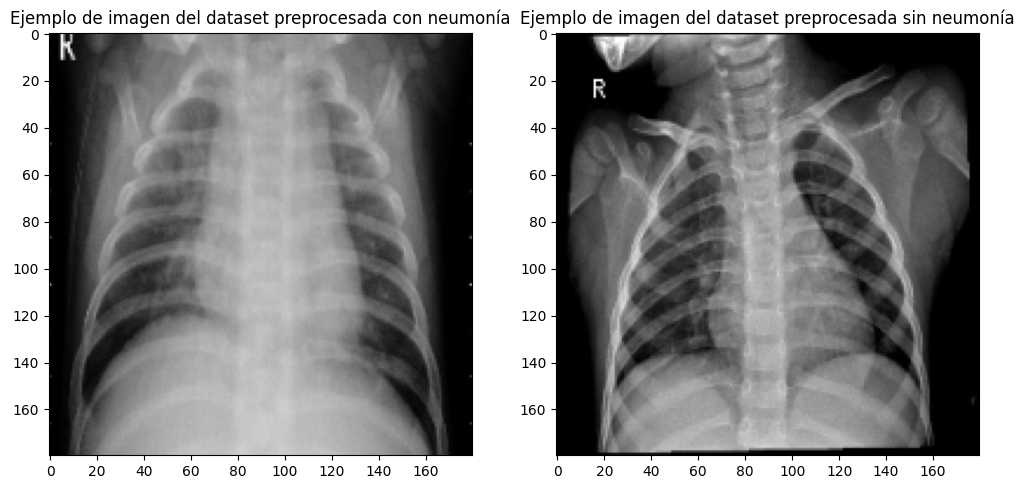

In [ ]:
plt.figure(figsize=(12, 10))
plt.subplot(1,2,1)
plt.title('Ejemplo de imagen del dataset preprocesada sin neumonía')
plt.imshow(X[9], cmap='gray', vmin=0, vmax=1)

plt.subplot(1,2,2)
plt.title('Ejemplo de imagen del dataset preprocesada con neumonía')
plt.imshow(X[6000], cmap='gray', vmin=0, vmax=1)

In [ ]:
#@title División del dataset en entrenamiento, validación y pruebas
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=230406, stratify=y)

# Para dividir el 80% restante en entrenamiento y validación, tomamos el 18.75% para escoger aproximadamente el 15% del dataset
# original (0.8 * 0.1875 = 0.15)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1875, random_state=230406, stratify=y_temp)

In [ ]:
#@title Ajuste para entrenamiento con CNNs en Keras/Tensorflow
# Las CNNs en Keras son estrictas con el formato de los datos que reciben, siempre deben recibir datos de 4 dimensiones
# (Número de imágenes, alto, ancho, canales). Como hemos preprocesado las imágenes en escala de grises, solo tienen 3 dimensiones
# (x, 180, 180) por lo que debemos agregar una cuarta dimensión extra --> (x, 180, 180, 1)
X_train = np.expand_dims(X_train, axis=-1)
X_val = np.expand_dims(X_val, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print(f'Dimensiones de los datos de entrenamiento: {X_train.shape}')
print(f'Dimensiones de los datos de validación: {X_val.shape}')
print(f'Dimensiones de los datos de prueba: {X_test.shape}')

Dimensiones de los datos de entrenamiento: (6823, 180, 180, 1)
Dimensiones de los datos de validación: (1575, 180, 180, 1)
Dimensiones de los datos de prueba: (2100, 180, 180, 1)
